In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_derivada_primeira_ordem.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
output_path = os.path.join(output_dir, 'espectros_deteccao_remocao_bandas_ruidosas.csv')

In [3]:
df = pd.read_csv(input_path)
data = df.values
data

array([[-1.22669230e+00, -1.22370233e+00, -1.18193011e+00, ...,
        -2.44663997e-02, -2.48113649e-02, -2.34797211e-02],
       [-1.22809136e+00, -1.22650100e+00, -1.18331519e+00, ...,
        -1.45590552e-02, -1.29546178e-02, -1.28041648e-02],
       [ 6.51925979e-03,  8.84239901e-03,  1.11429852e-02, ...,
        -3.92367290e-02, -3.38053645e-02, -2.34663678e-02],
       ...,
       [-2.26754826e-03, -3.06926652e-03, -3.67782485e-03, ...,
        -5.82452097e-04, -8.91227452e-04, -8.73533119e-04],
       [-4.17888269e-04, -1.01981406e-03, -1.57050202e-03, ...,
        -5.40913066e-03, -6.29463986e-03, -6.43230367e-03],
       [ 4.38405676e-04, -4.33175480e-04, -9.48755600e-04, ...,
         2.22633627e-03,  2.33278647e-03,  2.25953569e-03]],
      shape=(92480, 256))

In [4]:
# --- ANÁLISE DE VARIÂNCIA ---
variancias = np.var(data, axis=0)

# --- CRITÉRIO 1: EXTREMIDADES ESPECTRAIS ---
percentual_extremidades = 0.10  # 10% das bandas em cada extremidade
n_extremidades = int(data.shape[1] * percentual_extremidades)

# --- CRITÉRIO 2: LIMIAR DE VARIÂNCIA ---
limiar_variancia = 0.05 * np.max(variancias)  # 5% do máximo
limiar_centro = 0.01 * np.max(variancias)     # 1% do máximo (mais rigoroso para centro)

In [5]:
# --- IDENTIFICAÇÃO AUTOMÁTICA DE BANDAS PROBLEMÁTICAS ---
bandas_problematicas = []

# Bandas das extremidades com variância muito baixa
for i in range(n_extremidades):
    if variancias[i] < limiar_variancia:
        bandas_problematicas.append(i)
    if variancias[-(i+1)] < limiar_variancia:
        bandas_problematicas.append(data.shape[1] - (i+1))

# Bandas do centro com variância extremamente baixa
for i in range(n_extremidades, data.shape[1] - n_extremidades):
    if variancias[i] < limiar_centro:
        bandas_problematicas.append(i)

bandas_problematicas = sorted(set(bandas_problematicas))  # Remover duplicatas

In [7]:
# --- APLICAÇÃO AUTOMÁTICA DA FILTRAGEM ---
data_filtrada = np.delete(data, bandas_problematicas, axis=1)
colunas_filtradas = [c for i, c in enumerate(df.columns) if i not in bandas_problematicas]

df_filtrado = pd.DataFrame(data_filtrada, columns=colunas_filtradas)


In [8]:
# --- RELATÓRIO AUTOMÁTICO ---
print(f"\n=== RELATÓRIO DA FILTRAGEM AUTOMÁTICA ===")
print(f"Variância máxima: {np.max(variancias):.6f}")
print(f"Limiar extremidades: {limiar_variancia:.6f}")
print(f"Limiar centro: {limiar_centro:.6f}")
print(f"Bandas problemáticas identificadas: {len(bandas_problematicas)}")
print(f"Bandas úteis mantidas: {len(colunas_filtradas)}")
print(f"Redução: {len(bandas_problematicas)/data.shape[1]*100:.1f}% das bandas removidas")

if bandas_problematicas:
    print(f"\nBandas removidas: {bandas_problematicas}")
    print(f"Variâncias das bandas removidas:")
    for banda in bandas_problematicas:
        print(f"  Banda {banda}: {variancias[banda]:.6f}")

print(f"\n✅ Filtragem automática concluída!")
print(f"✅ Dimensões finais: {data_filtrada.shape}")
print(f"✅ Arquivo salvo em: {output_path}")


=== RELATÓRIO DA FILTRAGEM AUTOMÁTICA ===
Variância máxima: 0.199158
Limiar extremidades: 0.009958
Limiar centro: 0.001992
Bandas problemáticas identificadas: 36
Bandas úteis mantidas: 220
Redução: 14.1% das bandas removidas

Bandas removidas: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 24, 195, 196, 197, 198, 199, 200, 201, 206, 207, 208, 209, 210, 211, 212, 213, 214, 218, 220, 221, 222, 223]
Variâncias das bandas removidas:
  Banda 8: 0.009191
  Banda 9: 0.007724
  Banda 10: 0.008078
  Banda 11: 0.007319
  Banda 12: 0.007874
  Banda 13: 0.008232
  Banda 14: 0.008094
  Banda 15: 0.008559
  Banda 16: 0.007516
  Banda 17: 0.007280
  Banda 18: 0.008064
  Banda 19: 0.009003
  Banda 21: 0.009029
  Banda 22: 0.009554
  Banda 24: 0.008903
  Banda 195: 0.000911
  Banda 196: 0.000284
  Banda 197: 0.000210
  Banda 198: 0.000799
  Banda 199: 0.000991
  Banda 200: 0.000991
  Banda 201: 0.001604
  Banda 206: 0.001910
  Banda 207: 0.001435
  Banda 208: 0.001510
  Banda 209: 0.001029
  B

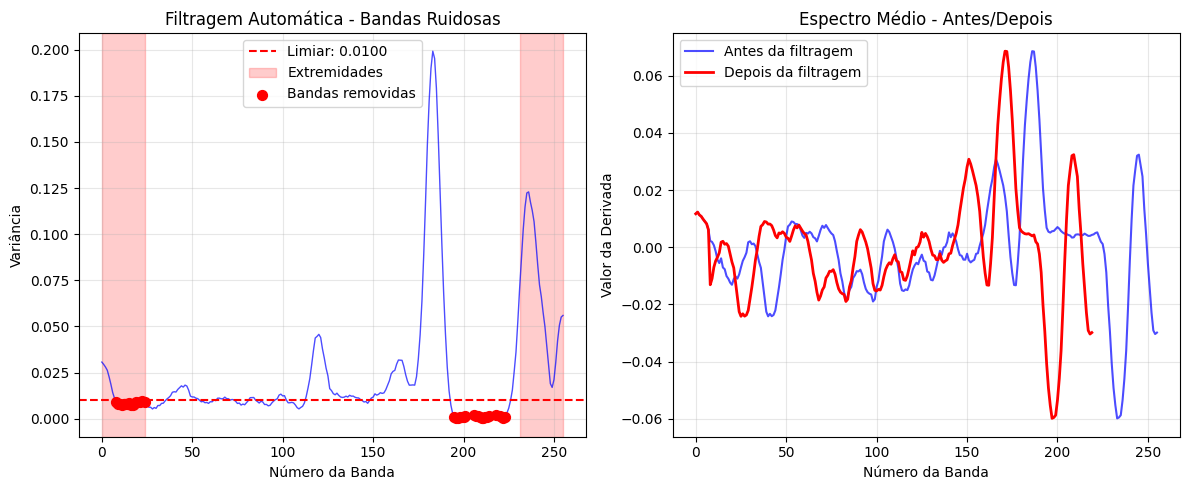

In [9]:
bandas_numeros = np.arange(len(variancias))
bandas_uteis_numeros = np.arange(len(colunas_filtradas))

plt.figure(figsize=(12, 5))

# Gráfico 1: Variância e bandas removidas
plt.subplot(1, 2, 1)
plt.plot(bandas_numeros, variancias, 'b-', alpha=0.7, linewidth=1)
plt.axhline(y=limiar_variancia, color='r', linestyle='--', label=f'Limiar: {limiar_variancia:.4f}')
plt.axvspan(0, n_extremidades-1, alpha=0.2, color='red', label='Extremidades')
plt.axvspan(data.shape[1]-n_extremidades, data.shape[1]-1, alpha=0.2, color='red')

if bandas_problematicas:
    plt.scatter(bandas_problematicas, [variancias[i] for i in bandas_problematicas], 
               color='red', s=50, zorder=5, label='Bandas removidas')

plt.xlabel('Número da Banda')
plt.ylabel('Variância')
plt.title('Filtragem Automática - Bandas Ruidosas')
plt.legend()
plt.grid(True, alpha=0.3)

# Gráfico 2: Comparação espectro médio
plt.subplot(1, 2, 2)
media_antes = np.mean(data, axis=0)
media_depois = np.mean(data_filtrada, axis=0)

plt.plot(bandas_numeros, media_antes, 'b-', alpha=0.7, label='Antes da filtragem')
plt.plot(bandas_uteis_numeros, media_depois, 'r-', label='Depois da filtragem', linewidth=2)

plt.xlabel('Número da Banda')
plt.ylabel('Valor da Derivada')
plt.title('Espectro Médio - Antes/Depois')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
